In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
file_count = 0
for dirname, _, filenames in os.walk('/kaggle/input'):
    file_count += len(filenames)
print(f"Trovati in totale {file_count} file in /kaggle/input")

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Trovati in totale 184906 file in /kaggle/input


In [5]:
import pandas as pd

phase_df = pd.read_csv('/kaggle/input/datasets/christiancorvino/cholec80-mr-sapienza/phase_annotations/video01-phase.txt', sep='\t')
print(phase_df.shape)
print(phase_df.head(10))
print(phase_df['Phase'].unique())

(43326, 2)
   Frame        Phase
0      0  Preparation
1      1  Preparation
2      2  Preparation
3      3  Preparation
4      4  Preparation
5      5  Preparation
6      6  Preparation
7      7  Preparation
8      8  Preparation
9      9  Preparation
['Preparation' 'CalotTriangleDissection' 'ClippingCutting'
 'GallbladderDissection' 'GallbladderPackaging' 'CleaningCoagulation'
 'GallbladderRetraction']


In [6]:
import pandas as pd

base_path = '/kaggle/input/datasets/christiancorvino/cholec80-mr-sapienza/phase_annotations'

phase_dfs = {}  # dizionario: {video_id: dataframe}

for i in range(1, 81):
    vid = f"video{i:02d}"
    file_path = f"{base_path}/{vid}-phase.txt"
    df = pd.read_csv(file_path, sep='\t')
    phase_dfs[vid] = df

print("Video caricati:", len(phase_dfs))
print(phase_dfs['video05'].shape)  # controllo di esempio su un altro video
print(phase_dfs['video80'].shape)

Video caricati: 80
(58601, 2)
(43101, 2)


In [7]:
all_phase_sets = set()
for vid, df in phase_dfs.items():
    all_phase_sets.add(tuple(sorted(df['Phase'].unique())))

print("Set unici di fasi trovati nel dataset:", all_phase_sets)

Set unici di fasi trovati nel dataset: {('CalotTriangleDissection', 'CleaningCoagulation', 'ClippingCutting', 'GallbladderDissection', 'GallbladderPackaging', 'GallbladderRetraction'), ('CalotTriangleDissection', 'ClippingCutting', 'GallbladderDissection', 'GallbladderPackaging', 'GallbladderRetraction', 'Preparation'), ('CalotTriangleDissection', 'CleaningCoagulation', 'ClippingCutting', 'GallbladderDissection', 'GallbladderPackaging', 'GallbladderRetraction', 'Preparation')}


In [8]:
all_phases_ref = {'Preparation', 'CalotTriangleDissection', 'ClippingCutting',
                   'GallbladderDissection', 'GallbladderPackaging',
                   'CleaningCoagulation', 'GallbladderRetraction'}

videos_with_missing_phases_count = 0

for vid, df in phase_dfs.items():
    phases_present = set(df['Phase'].unique())
    missing = all_phases_ref - phases_present
    if missing:
        videos_with_missing_phases_count += 1
if videos_with_missing_phases_count > 0:
    print(f"Ci sono {videos_with_missing_phases_count} video con fasi mancanti.")
else:
    print("Nessun video ha fasi mancanti.")

Ci sono 15 video con fasi mancanti.


In [9]:
from collections import Counter

phase_set_counts = Counter()
for vid, df in phase_dfs.items():
    phases_present = tuple(sorted(df['Phase'].unique()))
    phase_set_counts[phases_present] += 1
total_videos = sum(phase_set_counts.values())
unique_combinations = len(phase_set_counts)
print(f"Riepilogo: trovati {total_videos} video distribuiti in {unique_combinations} combinazioni di fasi diverse.")

Riepilogo: trovati 80 video distribuiti in 3 combinazioni di fasi diverse.


In [10]:
all_phases_ref = {'Preparation', 'CalotTriangleDissection', 'ClippingCutting',
                   'GallbladderDissection', 'GallbladderPackaging',
                   'CleaningCoagulation', 'GallbladderRetraction'}

missing_prep = []
missing_clean = []

for vid, df in phase_dfs.items():
    phases_present = set(df['Phase'].unique())
    missing = all_phases_ref - phases_present
    if 'Preparation' in missing:
        missing_prep.append(vid)
    if 'CleaningCoagulation' in missing:
        missing_clean.append(vid)

print("Video senza Preparation:", missing_prep)
print("Video senza CleaningCoagulation:", missing_clean)

Video senza Preparation: ['video10', 'video13', 'video19', 'video22', 'video23', 'video29', 'video32', 'video33', 'video38']
Video senza CleaningCoagulation: ['video21', 'video50', 'video65', 'video69', 'video71', 'video75']


In [11]:
import os

total_video_files = 0
folders_with_videos = 0
for root, dirs, files in os.walk('/kaggle/input'):
    video_files = [f for f in files if f.endswith(('.mp4', '.avi', '.mkv'))]
    if video_files:
        total_video_files += len(video_files)
        folders_with_videos += 1
print(f"Trovati {total_video_files} file video distribuiti in {folders_with_videos} cartelle.")

Trovati 80 file video distribuiti in 1 cartelle.


In [12]:
import cv2
import os

videos_base = '/kaggle/input/datasets/christiancorvino/cholec80-mr-sapienza/videos'
output_frames_base = '/kaggle/working/frames'
os.makedirs(output_frames_base, exist_ok=True)

TARGET_FPS = 1

def extract_frames(video_path, output_dir, target_fps=1, resize_to=(224, 224)):
    os.makedirs(output_dir, exist_ok=True)
    cap = cv2.VideoCapture(video_path)
    original_fps = cap.get(cv2.CAP_PROP_FPS)
    frame_interval = round(original_fps / target_fps)

    frame_idx = 0
    saved_idx = 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if frame_idx % frame_interval == 0:
            frame_small = cv2.resize(frame, resize_to)
            out_path = os.path.join(output_dir, f"frame_{saved_idx:06d}.jpg")
            cv2.imwrite(out_path, frame_small, [cv2.IMWRITE_JPEG_QUALITY, 85])
            saved_idx += 1
        frame_idx += 1
    cap.release()
    return saved_idx, frame_interval

# Test su UN SOLO video prima di lanciare tutto
vid = "video01"
video_path = f"{videos_base}/{vid}.mp4"
out_dir = f"{output_frames_base}/{vid}"
n_saved, interval = extract_frames(video_path, out_dir, TARGET_FPS)
print(f"{vid}: salvati {n_saved} frame, interval={interval}")

video01: salvati 1734 frame, interval=25


In [13]:
# estrai solo 3 video di test con la versione ridimensionata
for vid in ['video01', 'video02', 'video03']:
    video_path = f"{videos_base}/{vid}.mp4"
    out_dir = f"/kaggle/working/frames/{vid}"
    extract_frames(video_path, out_dir, target_fps=1, resize_to=(224,224))

!du -sh /kaggle/working/frames

KeyboardInterrupt: 

In [14]:
video_ids = [f"video{i:02d}" for i in range(1, 81)]
extraction_log = []

successful_extractions = 0
missing_videos = 0
total_frames_extracted = 0

for vid in video_ids:
    video_path = f"{videos_base}/{vid}.mp4"
    out_dir = f"{output_frames_base}/{vid}"
    
    if not os.path.exists(video_path):
        missing_videos += 1
        extraction_log.append({'video': vid, 'error': 'video non trovato'})
        continue
        
    n_saved, interval = extract_frames(video_path, out_dir, TARGET_FPS)
    extraction_log.append({'video': vid, 'n_frames_saved': n_saved, 'sampling_interval': interval})
    
    successful_extractions += 1
    total_frames_extracted += n_saved

print(f"Estrazione completata: {successful_extractions} video elaborati ({total_frames_extracted} frame totali estratti). {missing_videos} video non trovati/saltati.")

import pandas as pd
extraction_df = pd.DataFrame(extraction_log)
extraction_df.to_csv('/kaggle/working/extraction_log.csv', index=False)
print(extraction_df)

KeyboardInterrupt: 

In [15]:
import pandas as pd
import os

# --- path da aggiornare con quello trovato al punto 2 ---
frames_base = '/kaggle/input/datasets/giorgiachiaro/parte-1-estrazione/frames'  
phase_base = '/kaggle/input/datasets/christiancorvino/cholec80-mr-sapienza/phase_annotations'
extraction_log_path = f'{frames_base}/../extraction_log.csv'  # se l'hai salvato insieme ai frame

phase_to_int = {
    'Preparation': 0,
    'CalotTriangleDissection': 1,
    'ClippingCutting': 2,
    'GallbladderDissection': 3,
    'GallbladderPackaging': 4,
    'CleaningCoagulation': 5,
    'GallbladderRetraction': 6
}

# Ricarica extraction_log se l'hai pubblicato insieme al dataset,
# altrimenti lo ricalcoli velocemente contando i file (vedi sotto)
if os.path.exists(extraction_log_path):
    extraction_df = pd.read_csv(extraction_log_path)
else:
    # fallback: ricostruisci n_frames_saved contando i .jpg per ogni video
    rows = []
    for i in range(1, 81):
        vid = f"video{i:02d}"
        vid_dir = f"{frames_base}/{vid}"
        if os.path.exists(vid_dir):
            n = len([f for f in os.listdir(vid_dir) if f.endswith('.jpg')])
            rows.append({'video': vid, 'n_frames_saved': n, 'sampling_interval': 25})
    extraction_df = pd.DataFrame(rows)

print(extraction_df.shape)

(80, 3)


In [16]:
def build_label_table(vid, frame_interval, n_saved):
    phase_df = pd.read_csv(f"{phase_base}/{vid}-phase.txt", sep='\t')
    rows = []
    for saved_idx in range(n_saved):
        original_frame_idx = saved_idx * frame_interval
        if original_frame_idx >= len(phase_df):
            break
        phase_str = phase_df.iloc[original_frame_idx]['Phase']
        rows.append({
            'video_id': vid,
            'frame_path': f"{frames_base}/{vid}/frame_{saved_idx:06d}.jpg",
            'phase_str': phase_str,
            'phase_label': phase_to_int[phase_str]
        })
    return rows

all_rows = []
for _, row in extraction_df.iterrows():
    vid = row['video']
    rows = build_label_table(vid, row['sampling_interval'], row['n_frames_saved'])
    all_rows.extend(rows)

dataset_df = pd.DataFrame(all_rows)
print(dataset_df.shape)
print(dataset_df.head())
dataset_df.to_csv('/kaggle/working/full_dataset.csv', index=False)

(184578, 4)
  video_id                                         frame_path    phase_str  \
0  video01  /kaggle/input/datasets/giorgiachiaro/parte-1-e...  Preparation   
1  video01  /kaggle/input/datasets/giorgiachiaro/parte-1-e...  Preparation   
2  video01  /kaggle/input/datasets/giorgiachiaro/parte-1-e...  Preparation   
3  video01  /kaggle/input/datasets/giorgiachiaro/parte-1-e...  Preparation   
4  video01  /kaggle/input/datasets/giorgiachiaro/parte-1-e...  Preparation   

   phase_label  
0            0  
1            0  
2            0  
3            0  
4            0  


In [17]:
print("Totale frame nel dataset:", dataset_df.shape[0])
print("Totale atteso:", extraction_df['n_frames_saved'].sum())
print("Numero video distinti:", dataset_df['video_id'].nunique())
print(dataset_df['phase_str'].value_counts())

Totale frame nel dataset: 184578
Totale atteso: 184578
Numero video distinti: 80
phase_str
CalotTriangleDissection    74826
GallbladderDissection      58433
CleaningCoagulation        14335
ClippingCutting            14080
Preparation                 8574
GallbladderPackaging        7618
GallbladderRetraction       6712
Name: count, dtype: int64


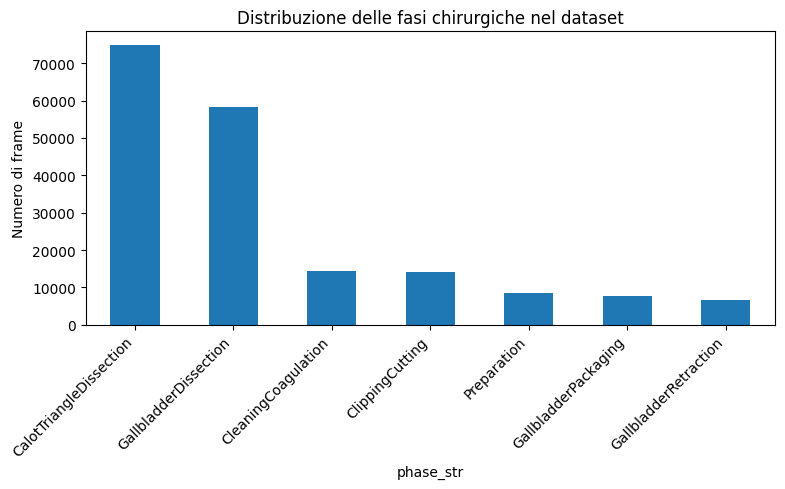

In [18]:
import matplotlib.pyplot as plt

counts = dataset_df['phase_str'].value_counts()
plt.figure(figsize=(8,5))
counts.plot(kind='bar')
plt.ylabel('Numero di frame')
plt.title('Distribuzione delle fasi chirurgiche nel dataset')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('/kaggle/working/class_distribution.png')
plt.show()

In [19]:
video_ids = dataset_df['video_id'].unique().tolist()

missing_prep = []
missing_clean = []
normal_videos = []

for vid in video_ids:
    phases_in_video = set(dataset_df[dataset_df['video_id'] == vid]['phase_str'].unique())
    if 'Preparation' not in phases_in_video:
        missing_prep.append(vid)
    elif 'CleaningCoagulation' not in phases_in_video:
        missing_clean.append(vid)
    else:
        normal_videos.append(vid)

print(len(normal_videos), len(missing_prep), len(missing_clean))

65 9 6


In [23]:
TRAIN_IDS = [f"video{i:02d}" for i in range(1, 33)]   # 32 video
VAL_IDS   = [f"video{i:02d}" for i in range(33, 41)]  # 8 video
TEST_IDS  = [f"video{i:02d}" for i in range(41, 81)]  # 40 video

assert set(TRAIN_IDS) & set(VAL_IDS) == set()
assert set(TRAIN_IDS) & set(TEST_IDS) == set()
assert set(VAL_IDS) & set(TEST_IDS) == set()

train_df = dataset_df[dataset_df['video_id'].isin(TRAIN_IDS)].reset_index(drop=True)
val_df   = dataset_df[dataset_df['video_id'].isin(VAL_IDS)].reset_index(drop=True)
test_df  = dataset_df[dataset_df['video_id'].isin(TEST_IDS)].reset_index(drop=True)

train_df.to_csv('/kaggle/working/train.csv', index=False)
val_df.to_csv('/kaggle/working/val.csv', index=False)
test_df.to_csv('/kaggle/working/test.csv', index=False)

print(train_df.shape, val_df.shape, test_df.shape)

(71032, 4) (15312, 4) (98234, 4)


In [24]:
print("Train:\n", train_df['phase_str'].value_counts())
print("\nVal:\n", val_df['phase_str'].value_counts())
print("\nTest:\n", test_df['phase_str'].value_counts())

Train:
 phase_str
CalotTriangleDissection    29730
GallbladderDissection      20046
ClippingCutting             6139
CleaningCoagulation         5979
Preparation                 3104
GallbladderPackaging        3084
GallbladderRetraction       2950
Name: count, dtype: int64

Val:
 phase_str
CalotTriangleDissection    7156
GallbladderDissection      4073
CleaningCoagulation        1243
ClippingCutting            1190
Preparation                 654
GallbladderPackaging        632
GallbladderRetraction       364
Name: count, dtype: int64

Test:
 phase_str
CalotTriangleDissection    37940
GallbladderDissection      34314
CleaningCoagulation         7113
ClippingCutting             6751
Preparation                 4816
GallbladderPackaging        3902
GallbladderRetraction       3398
Name: count, dtype: int64


In [25]:
# 1. Class weights
import numpy as np

class_counts = train_df['phase_label'].value_counts().sort_index()
total = class_counts.sum()
n_classes = len(class_counts)
class_weights = total / (n_classes * class_counts)
class_weights.to_csv('/kaggle/working/class_weights.csv')
print(class_weights)

phase_label
0    3.269146
1    0.341319
2    1.652945
3    0.506207
4    3.290346
5    1.697178
6    3.439806
Name: count, dtype: float64


In [26]:
# Christian: devo solo runnare questo, upload del dataset delle features come dataset kaggle e 
# poi anche nel mio notebook, infine runnare il mio quello forkato

import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
import numpy as np
import os

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 1. Carica ResNet50 come estrattore di feature
resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
resnet = nn.Sequential(*list(resnet.children())[:-1])
resnet = resnet.to(DEVICE).eval()

img_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 2. Path ai frame estratti e alle annotazioni
frames_base = '/kaggle/input/datasets/giorgiachiaro/parte-1-estrazione/frames'
phase_base = '/kaggle/input/datasets/christiancorvino/cholec80-mr-sapienza/phase_annotations'
out_dir = '/kaggle/working/features'
os.makedirs(out_dir, exist_ok=True)

phase_to_int = {
    'Preparation': 0, 'CalotTriangleDissection': 1, 'ClippingCutting': 2,
    'GallbladderDissection': 3, 'GallbladderPackaging': 4,
    'CleaningCoagulation': 5, 'GallbladderRetraction': 6
}

# 3. Estrai feature da ogni video
BATCH = 64
videos_processed = 0
videos_skipped = 0
total_features_saved = 0

for vid_id in range(1, 81):
    vid = f"video{vid_id:02d}"
    frame_dir = os.path.join(frames_base, vid)
    
    if not os.path.isdir(frame_dir):
        videos_skipped += 1
        continue

    frame_files = sorted([f for f in os.listdir(frame_dir) if f.endswith('.jpg')])
    
    # Estrai feature
    batch, feats = [], []
    for f in frame_files:
        img = Image.open(os.path.join(frame_dir, f)).convert('RGB')
        batch.append(img_transform(img))
        if len(batch) >= BATCH:
            with torch.no_grad():
                out = resnet(torch.stack(batch).to(DEVICE))
            feats.append(out.squeeze(-1).squeeze(-1).cpu().numpy())
            batch = []
    if batch:
        with torch.no_grad():
            out = resnet(torch.stack(batch).to(DEVICE))
        feats.append(out.squeeze(-1).squeeze(-1).cpu().numpy())

    features = np.concatenate(feats, axis=0)

    # Costruisci le labels allineate ai frame estratti
    phase_df = pd.read_csv(f"{phase_base}/{vid}-phase.txt", sep='\t')
    interval = 25  # 25fps → 1fps
    labels = []
    for i in range(len(frame_files)):
        orig_idx = i * interval
        if orig_idx < len(phase_df):
            labels.append(phase_to_int[phase_df.iloc[orig_idx]['Phase']])
    labels = np.array(labels)

    # Allinea lunghezze
    min_len = min(len(features), len(labels))
    np.save(os.path.join(out_dir, f"{vid}_features.npy"), features[:min_len])
    np.save(os.path.join(out_dir, f"{vid}_labels.npy"), labels[:min_len])
    
    # Aggiorna i contatori invece di stampare
    videos_processed += 1
    total_features_saved += min_len

print(f"Estrazione feature completata: {videos_processed} video processati con successo ({total_features_saved} frame totali). {videos_skipped} video saltati per frame mancanti.")
del resnet
torch.cuda.empty_cache()
print(f"\nFeature salvate in {out_dir}. Pubblica questa cartella come dataset Kaggle!")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 210MB/s]


Estrazione feature completata: 80 video processati con successo (184578 frame totali). 0 video saltati per frame mancanti.

Feature salvate in /kaggle/working/features. Pubblica questa cartella come dataset Kaggle!
